# ModelResults

> A lightweight wrapper around pandas `DataFrames`, that allows for some fancy slicing/indexing and easy plotting.

In [ ]:
#| default_exp modelresults

In [ ]:
#| export

import pandas as pd
import sympy as sp

In [ ]:
from SFCmodeler.term import Term, Variable, Parameter
from SFCmodeler.SFCmodel import SFCmodel

In [ ]:
#| export

class ModelResults():
  def __init__(self, results,index=None,start_period="2000",freq="Y",debuglist=False):
    self.debuglist = debuglist

    if isinstance(results, pd.Series):
      results = results.to_frame()
    if isinstance(results,pd.DataFrame):
      self.df = results
    else:
      if isinstance(results, dict):
        results = [results]
      if index is None and not debuglist:
        index = pd.period_range(start=start_period,periods=len(results),freq=freq)
      self.df = pd.DataFrame(results, index=index)



  def __getitem__(self, key):
    if isinstance(key, int):
      return ModelResults(self.df.iloc[[key]])
    elif isinstance(key, str):
        return ModelResults(self.df.loc[[key]])
    elif isinstance(key,slice):
      if isinstance(key.start, int) or isinstance(key.stop, int):
        return ModelResults(self.df.iloc[key])

      indexer = self.df.index.slice_indexer(
                start=key.start,
                end=key.stop,
                step=key.step
            )
      return ModelResults(self.df.iloc[indexer])
    else:
      if not isinstance(key, list):
        key = [key]
      series_dict = {}
      for item in key:
        if item in self.df.columns:
          series_dict[item] = self.df[item]
        else:
          # assume it's an expression
          terms = list(item.free_symbols)
          func = sp.lambdify(terms, item, 'numpy')
          series_dict[item] = func(*[self.df[term] if term in self.df.columns else self.df[term.unlagged].shift(-term.lag) for term in terms])
      return ModelResults(pd.DataFrame(series_dict),index=self.df.index)

  def __repr__(self):
    return self.df.__repr__()

  def _repr_markdown_(self):
    return self.df.rename(columns=lambda col:sp.latex(col,mode="inline")).to_markdown()

  _repr_html_ = None

  def __str__(self):
    return self.df.__str__()

  def plot(self, vars_list=None, filename=None, **kwargs):
    if isinstance(vars_list, list):
      if isinstance(vars_list[0], list):
        # list of lists
        import math
        rows = math.ceil(len(vars_list)/2)
        cols = 2

        fig = plt.figure(figsize=(15, 5*rows))

        i=0
        for vars, kwarg in zip(vars_list, [{key : value[i] for key, value in kwargs.items()} for i in range(len(vars_list))]):
          axes = fig.add_subplot(rows, cols, i+1)
          axes = self[vars].plot(ax=axes,**kwarg)
          i+=1

        fig.tight_layout()

        if filename is not None:
          plt.savefig(filename, dpi=160)
          try:
            from google.colab import files
            files.download(filename)
          except ImportError:
              pass

        plt.close(fig)
        return fig

    if vars_list is None:
      return self.df.rename(columns=lambda col:sp.latex(col,mode="inline")).plot(**kwargs)
    return self[vars_list].plot(**kwargs)

  def growth(self):
    return (self.pct_change()*100)[1:]


  def __len__(self):
    return len(self.df)

  def __getattr__(self,name):
    return getattr(self.df,name)

`ModelResults` is a small wrapper around a standard pandas `DataFrame`, that just adds some nicer indexing, slicing, and plotting.

You won't usually create one yourself, and instead an `SFCmodel` will store one in the `.data` property:

In [ ]:
Variable.default_value = 10

C = Variable("C","Consumption")
T = Variable("T","Taxes")
V = Variable("V","Wealth",100)
Y = Variable("Y","GDP")

alpha1 = Parameter("alpha_1","MPC out of income",0.6)
alpha2 = Parameter("alpha_2","MPC out of wealth",0.4)
G = Parameter("G","Government spending",5)
theta = Parameter("theta","Tax rate",0.2)

model = SFCmodel(
    [
        C << alpha1 * (Y - T) + alpha2 * V(-1),
        Y << C + G,
        T << theta * Y,
        V << V(-1) + Y - T - C
    ]
)

model.solve(5)

model.data

  0%|          | 0/6 [00:00<?, ?it/s]

|      |     $C$ |   $G$ |     $T$ |      $V$ |   $V_{-1}$ |     $Y$ |   $\alpha_{1}$ |   $\alpha_{2}$ |   $\theta$ |
|:-----|--------:|------:|--------:|---------:|-----------:|--------:|---------------:|---------------:|-----------:|
| 2000 | 10      |     5 | 10      | 100      |   100      | 10      |            0.6 |            0.4 |        0.2 |
| 2001 | 81.5385 |     5 | 17.3077 |  87.6923 |   100      | 86.5385 |            0.6 |            0.4 |        0.2 |
| 2002 | 72.071  |     5 | 15.4142 |  77.2781 |    87.6923 | 77.071  |            0.6 |            0.4 |        0.2 |
| 2003 | 64.0601 |     5 | 13.812  |  68.4661 |    77.2781 | 69.0601 |            0.6 |            0.4 |        0.2 |
| 2004 | 57.2816 |     5 | 12.4563 |  61.0098 |    68.4661 | 62.2816 |            0.6 |            0.4 |        0.2 |
| 2005 | 51.546  |     5 | 11.3092 |  54.7006 |    61.0098 | 56.546  |            0.6 |            0.4 |        0.2 |

In [ ]:
#| hide

Note that the column headers display with rendered LaTeX in Jupyter notebooks or Google Colab. You should use the `variables` and `parameters` to index:

In [ ]:
model.data[Y]

|      |     $Y$ |
|:-----|--------:|
| 2000 | 10      |
| 2001 | 86.5385 |
| 2002 | 77.071  |
| 2003 | 69.0601 |
| 2004 | 62.2816 |
| 2005 | 56.546  |

In [ ]:
model.data[alpha1]

|      |   $\alpha_{1}$ |
|:-----|---------------:|
| 2000 |            0.6 |
| 2001 |            0.6 |
| 2002 |            0.6 |
| 2003 |            0.6 |
| 2004 |            0.6 |
| 2005 |            0.6 |

As well as lists:

In [ ]:
model.data[[Y, alpha1]]

|      |     $Y$ |   $\alpha_{1}$ |
|:-----|--------:|---------------:|
| 2000 | 10      |            0.6 |
| 2001 | 86.5385 |            0.6 |
| 2002 | 77.071  |            0.6 |
| 2003 | 69.0601 |            0.6 |
| 2004 | 62.2816 |            0.6 |
| 2005 | 56.546  |            0.6 |

In [ ]:
#| hide
from SFCmodeler.modelresults import ModelResults as exportedModelResults
assert isinstance(model.data[Y], exportedModelResults)
assert isinstance(model.data[alpha1], exportedModelResults)
assert isinstance(model.data[[Y, alpha1]], exportedModelResults)
assert model.data[[Y,alpha1]][Y].df.equals(model.data[Y].df)
assert model.data[[Y,alpha1]][alpha1].df.equals(model.data[alpha1].df)

You can also do a custom calculation using a formula for the index (with any valid `Sympy` expression):

In [ ]:
model.data[C+G]

|      |   $G + C$ |
|:-----|----------:|
| 2000 |   15      |
| 2001 |   86.5385 |
| 2002 |   77.071  |
| 2003 |   69.0601 |
| 2004 |   62.2816 |
| 2005 |   56.546  |

In [ ]:
#| hide
assert isinstance(model.data[C+G], exportedModelResults)
assert (model.data[C+G].squeeze() == (model.data[C].squeeze() + model.data[G].squeeze())).all()

Including lags:

In [ ]:
model.data[[Y,Y(-1)]]

|      |     $Y$ |   $Y_{-1}$ |
|:-----|--------:|-----------:|
| 2000 | 10      |   nan      |
| 2001 | 86.5385 |    10      |
| 2002 | 77.071  |    86.5385 |
| 2003 | 69.0601 |    77.071  |
| 2004 | 62.2816 |    69.0601 |
| 2005 | 56.546  |    62.2816 |

In [ ]:
#| hide
assert isinstance(model.data[Y(-1)], exportedModelResults)
assert isinstance(model.data[[Y,Y(-1)]], exportedModelResults)
assert (model.data[Y].shift(1).iloc[1:].squeeze() == model.data[Y(-1)].df.iloc[1:].squeeze()).all()

That's for viewing columns. To index by specific rows, you can use either the row number or the period name:

In [ ]:
model.data["2002"]

|      |    $C$ |   $G$ |     $T$ |     $V$ |   $V_{-1}$ |    $Y$ |   $\alpha_{1}$ |   $\alpha_{2}$ |   $\theta$ |
|:-----|-------:|------:|--------:|--------:|-----------:|-------:|---------------:|---------------:|-----------:|
| 2002 | 72.071 |     5 | 15.4142 | 77.2781 |    87.6923 | 77.071 |            0.6 |            0.4 |        0.2 |

In [ ]:
model.data["2002":"2004"]

|      |     $C$ |   $G$ |     $T$ |     $V$ |   $V_{-1}$ |     $Y$ |   $\alpha_{1}$ |   $\alpha_{2}$ |   $\theta$ |
|:-----|--------:|------:|--------:|--------:|-----------:|--------:|---------------:|---------------:|-----------:|
| 2002 | 72.071  |     5 | 15.4142 | 77.2781 |    87.6923 | 77.071  |            0.6 |            0.4 |        0.2 |
| 2003 | 64.0601 |     5 | 13.812  | 68.4661 |    77.2781 | 69.0601 |            0.6 |            0.4 |        0.2 |
| 2004 | 57.2816 |     5 | 12.4563 | 61.0098 |    68.4661 | 62.2816 |            0.6 |            0.4 |        0.2 |

In [ ]:
model.data[2]

|      |    $C$ |   $G$ |     $T$ |     $V$ |   $V_{-1}$ |    $Y$ |   $\alpha_{1}$ |   $\alpha_{2}$ |   $\theta$ |
|:-----|-------:|------:|--------:|--------:|-----------:|-------:|---------------:|---------------:|-----------:|
| 2002 | 72.071 |     5 | 15.4142 | 77.2781 |    87.6923 | 77.071 |            0.6 |            0.4 |        0.2 |

In [ ]:
model.data[2:4]

|      |     $C$ |   $G$ |     $T$ |     $V$ |   $V_{-1}$ |     $Y$ |   $\alpha_{1}$ |   $\alpha_{2}$ |   $\theta$ |
|:-----|--------:|------:|--------:|--------:|-----------:|--------:|---------------:|---------------:|-----------:|
| 2002 | 72.071  |     5 | 15.4142 | 77.2781 |    87.6923 | 77.071  |            0.6 |            0.4 |        0.2 |
| 2003 | 64.0601 |     5 | 13.812  | 68.4661 |    77.2781 | 69.0601 |            0.6 |            0.4 |        0.2 |

And of course you can do both:

In [ ]:
model.data[[Y,C(-1),alpha1*Y]][2:4]

|      |     $Y$ |   $C_{-1}$ |   $\alpha_{1} Y$ |
|:-----|--------:|-----------:|-----------------:|
| 2002 | 77.071  |    81.5385 |          46.2426 |
| 2003 | 69.0601 |    72.071  |          41.436  |

In [ ]:
#| hide
assert isinstance(model.data["2002"], exportedModelResults)
assert isinstance(model.data["2002":"2005"], exportedModelResults)
assert isinstance(model.data[2], exportedModelResults)
assert isinstance(model.data[2:4], exportedModelResults)
assert model.data["2002"].df.equals(model.data[2].df)
assert model.data["2002":"2004"].df.equals(model.data[2:5].df) # note the 5
assert isinstance(model.data[[Y,C(-1),alpha1*Y]][2:4], exportedModelResults)

The other thing that `ModelResults` can simplify for you is plotting.

<Axes: >

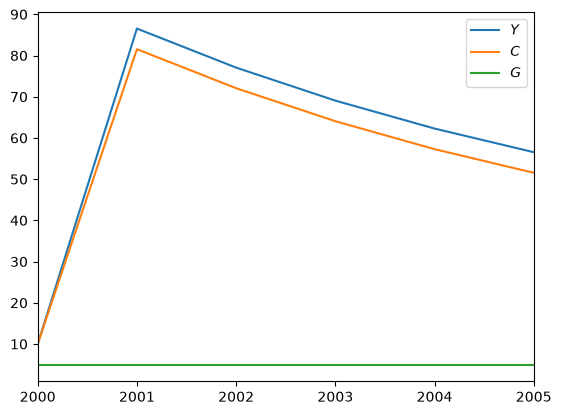

In [ ]:
model.data[[Y,C,G]].plot()

**PUT MORE ON PLOTTING HERE!!!**

Finally, `ModelResults` really is just a thin wrapper over the `DataFrame`. If you should need to get it directly, you can do `.df`:

In [ ]:
model.data.df

,C,G,T,V,V_{-1},Y,alpha_1,alpha_2,theta
2000,10.000000,5.0,10.000000,100.000000,100.000000,10.000000,0.6,0.4,0.2
2001,81.538462,5.0,17.307692,87.692308,100.000000,86.538462,0.6,0.4,0.2
2002,72.071006,5.0,15.414201,77.278107,87.692308,77.071006,0.6,0.4,0.2
2003,64.060082,5.0,13.812016,68.466090,77.278107,69.060082,0.6,0.4,0.2
2004,57.281608,5.0,12.456322,61.009769,68.466090,62.281608,0.6,0.4,0.2
2005,51.545976,5.0,11.309195,54.700573,61.009769,56.545976,0.6,0.4,0.2


But, any function calls not mentioned above on the `ModelResults` object will get forwarded to the underlying dataframe, e.g.

In [ ]:
model.data.pct_change()

,C,G,T,V,V_{-1},Y,alpha_1,alpha_2,theta
2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2001,7.153846,0.0,0.730769,-0.123077,0.000000,7.653846,0.0,0.0,0.0
2002,-0.116110,0.0,-0.109402,-0.118758,-0.123077,-0.109402,0.0,0.0,0.0
2003,-0.111153,0.0,-0.103942,-0.114030,-0.118758,-0.103942,0.0,0.0,0.0
2004,-0.105814,0.0,-0.098153,-0.108905,-0.114030,-0.098153,0.0,0.0,0.0
2005,-0.100130,0.0,-0.092092,-0.103413,-0.108905,-0.092092,0.0,0.0,0.0


Note that if the function returns a `DataFrame`, it will *not* automatically get wrapped again as `ModelResults`, therefore you should do any fancy indexing *prior* to calling a `df` method, or else re-wrap it yourself:

In [ ]:
ModelResults(model.data.pct_change())

|      |        $C$ |   $G$ |         $T$ |        $V$ |   $V_{-1}$ |         $Y$ |   $\alpha_{1}$ |   $\alpha_{2}$ |   $\theta$ |
|:-----|-----------:|------:|------------:|-----------:|-----------:|------------:|---------------:|---------------:|-----------:|
| 2000 | nan        |   nan | nan         | nan        | nan        | nan         |            nan |            nan |        nan |
| 2001 |   7.15385  |     0 |   0.730769  |  -0.123077 |   0        |   7.65385   |              0 |              0 |          0 |
| 2002 |  -0.11611  |     0 |  -0.109402  |  -0.118758 |  -0.123077 |  -0.109402  |              0 |              0 |          0 |
| 2003 |  -0.111153 |     0 |  -0.103942  |  -0.11403  |  -0.118758 |  -0.103942  |              0 |              0 |          0 |
| 2004 |  -0.105814 |     0 |  -0.0981533 |  -0.108905 |  -0.11403  |  -0.0981533 |              0 |              0 |          0 |
| 2005 |  -0.10013  |     0 |  -0.0920919 |  -0.103413 |  -0.108905 |  -0.0920919 |              0 |              0 |          0 |

In [ ]:
#| hide
assert isinstance(model.data.df, pd.DataFrame)
assert isinstance(model.data.pct_change(), pd.DataFrame)

In [ ]:
#| hide
import nbdev; nbdev.nbdev_export()